# mdCIF from the command line

> **New to mdCIF?** Start with [1_basic](../1_basic/1_basic.ipynb). It explains each step (PCA,
> clustering, medoids, modes) and what ends up in the file. This notebook runs the same steps
> from a terminal.

The command line comes down to four commands:

| Command | What it does |
|---|---|
| `mdcif build` | turns a trajectory into an mdCIF file: PCA, clustering, then a medoid and modes for each state (1_basic, sections 2–4) |
| `mdcif info` | summarises what a file holds |
| `mdcif validate` | checks a file against the PDBx, IHM and mdCIF dictionaries |
| `mdcif landscape` | plots the frames on PCs 1–3, from the file alone |

Each `!` line below is one terminal command. In a terminal, leave out the `!` and activate the
environment first (`conda activate mdcif`). A `\` at the end of a line continues the command on the
next line (bash; PowerShell uses a backtick). Everything the commands write goes into this
folder. The whole notebook runs in about a minute.

In [1]:
import os
import sysconfig

from IPython.display import Image

# Notebook only: run the mdcif command of this kernel's environment (in a terminal,
# `conda activate mdcif` does that), without another Python's packages on PYTHONPATH.
os.environ["PATH"] = sysconfig.get_path("scripts") + os.pathsep + os.environ["PATH"]
os.environ.pop("PYTHONPATH", None)
os.environ.setdefault("OMP_NUM_THREADS", "4")   # be polite to shared nodes

TOP = "../../data/3gb1/meld/3gb1_HMR.prmtop"     # Amber topology of the GB1 MELD run
TRAJ = "../../data/3gb1/meld/meld.nc.001"        # replica 1, 300 K (2 GB, not in git)

`$TOP` and `$TRAJ` in the commands are these two paths. In a terminal, set them once:

```bash
TOP=../../data/3gb1/meld/3gb1_HMR.prmtop
TRAJ=../../data/3gb1/meld/meld.nc.001
```

`mdcif --help` lists the commands; `mdcif build --help` lists every option of one of them.

In [2]:
!mdcif --help

                                                                                
 Usage: mdcif [OPTIONS] COMMAND [ARGS]...                                       
                                                                                
 Build, validate and inspect mdcif files.                                       
                                                                                


╭─ Options ────────────────────────────────────────────────────────────────────╮
│ --install-completion          Install completion for the current shell.      │
│ --show-completion             Show completion for the current shell, to copy │
│                               it or customize the installation.              │
│ --help                        Show this message and exit.                    │
╰──────────────────────────────────────────────────────────────────────────────╯
╭─ Commands ───────────────────────────────────────────────────────────────────╮
│ build      Cluster a trajectory, compute global and per-cluster modes and    │
│            write an mdcif file.                                              │
│ validate   Validate a file against the PDBx, IHM and mdcif dictionaries.     │
│ info       Summarize models, provenance and modes stored in an mdcif file.   │
│ landscape  Plot the frames on global PCs 1-3, coloured by cluster, from the  │
│            file alone.    

## 1. Build a file

| Argument | Meaning |
|---|---|
| `$TOP $TRAJ` | the topology, then one or more trajectory files (several = replicas, read one after another) |
| `--provenance provenance.yaml` | how the simulation was run (engine, force field, temperature…). Its `reference_PDB_id: 3GB1` makes the file an edited copy of that PDB entry, as in 1_basic. For your own run, start from [`provenance_template.yaml`](../../provenance_template.yaml) |
| `--start 25000 --step 10` | skip the first 25,000 frames (50 ns), then use every 10th |
| `--output gb1.cif` | the file to write; a `.bcif` name gives BinaryCIF, about half the size |

In [3]:
!mdcif build $TOP $TRAJ --provenance provenance.yaml \
    --start 25000 --step 10 --output gb1.cif

gb1.cif: 17683 frames, 56 analysis atoms, 435 deposited atoms
  global PCA var% 60/11/8 (cum 79%)
  clustering: HDBSCAN on PCA projection (global PCs 1-3), min_cluster_size 177, min_samples 177, cluster_selection eom, 2 clusters
  model 1: 16847 frames (95.3%), medoid frame 142700, t = 285.402 ns, precision 1.61 A, RMSD to PDB 3GB1 model 1 2.61 A, modes var% 26/20/8 (cum 54%)
  model 2:   836 frames ( 4.7%), medoid frame 127120, t = 254.242 ns, precision 0.93 A, RMSD to PDB 3GB1 model 1 9.04 A, modes var% 20/14/9 (cum 43%)
  timings: read+pca 1.6s, cluster 3.0s, modes 0.5s, reference 0.2s, write 0.1s


The report, line by line: the share of the motion along PCs 1–3 of the whole run; the
clustering (HDBSCAN on PCs 1–3 by default); then one line per model (state) with its frames, its
medoid, its precision, its Cα RMSD to 3GB1 and each of its three modes' share of the state's
motion. This is the same file that 1_basic writes.

## 2. Look inside, and check

In [4]:
!mdcif info gb1.cif

gb1.cif: Protein G B1 domain (PDB 3GB1) folded with MELD x Amber: 300 K replica ensemble
  simulation: force_field=ff19SB, water_model=implicit: GB-Neck2 (igb=8, mbondi3 radii), ensemble=NVT, temperature_K=300.0, timestep_fs=4.0, length_ns=403.65, n_replicas=30, save_interval_ps=2.0, enhanced_sampling=MELD: temperature + Hamiltonian replica exchange
  global: 3 PCA modes of 17683 frames on 56 atoms, var% 60/11/8
  projections: 5000 frames on global modes 1-3
  model 1: Cluster 1 medoid (frame 142700, t = 285.402 ns), 435 atoms, 16847 frames, precision 1.61 A, 3 PCA modes on 56 atoms, var% 26/20/8
      16847 of 17683 frames (95.3%); medoid CA RMSD to PDB 3GB1 model 1 2.61 A
  model 2: Cluster 2 medoid (frame 127120, t = 254.242 ns), 435 atoms, 836 frames, precision 0.93 A, 3 PCA modes on 56 atoms, var% 20/14/9
      836 of 17683 frames (4.7%); medoid CA RMSD to PDB 3GB1 model 1 9.04 A


In [5]:
!mdcif validate gb1.cif

gb1.cif: valid (PDBx + IHM + mdcif_ext, mode checks)


The first `validate` downloads the PDBx and IHM dictionaries and caches them in
`~/.cache/mdcif`.

## 3. Plot the landscape

wrote gb1_landscape.png


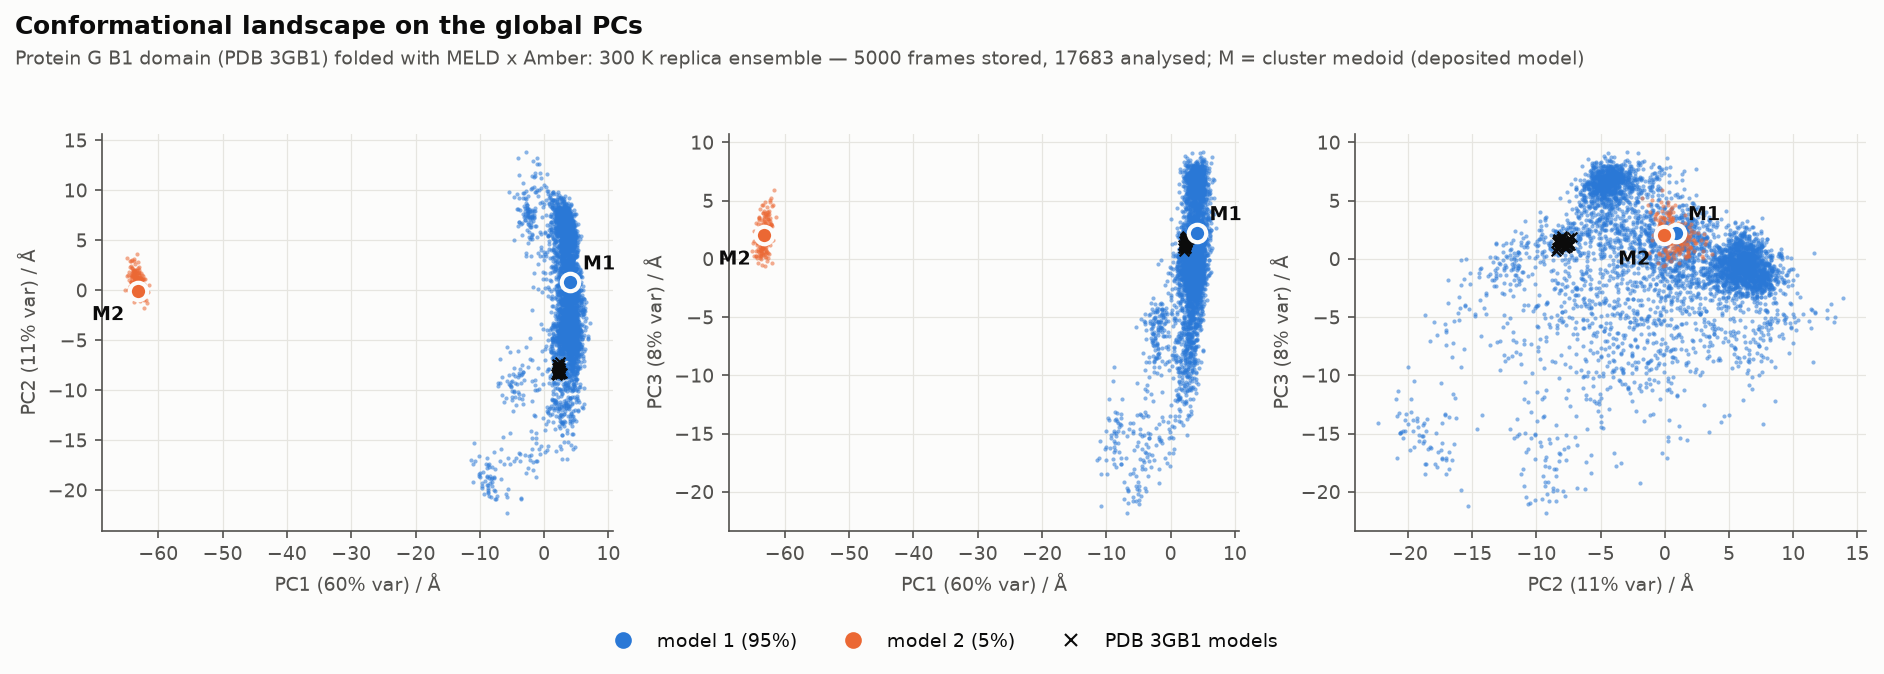

In [6]:
!mdcif landscape gb1.cif --reference 3GB1
Image("gb1_landscape.png", width=900)

The plot uses nothing but the file: the stored frames on PCs 1–3, coloured by state (`noise` =
in no state). M1 and M2 mark the models; × marks the 32 NMR models of 3GB1, placed on the same
PCs (`--reference`). `--output` sets another file name.

## 4. Changing the defaults

The options you will use most (all of them: `mdcif build --help`):

| Option | Default | What it does |
|---|---|---|
| `--cluster-selection leaf` | `eom` | HDBSCAN splits the states into smaller substates and leaves more frames as noise |
| `--min-cluster-size N` | 1% of the frames, at least 25 | HDBSCAN: the smallest state, in frames |
| `--max-models N` | all | keep only the N most populated states |
| `--labels FILE` | – | your own clustering instead of HDBSCAN (below) |
| `--n-modes N` | 3 | modes stored for each state |
| `--selection "name CA"` | from the YAML | atoms used for PCA and modes (MDAnalysis selection) |
| `--mass-weighted` | from the YAML | quasi-harmonic (mass-weighted) modes |
| `--reference ID` | from the YAML | PDB ID or mmCIF file to start the file from |
| `--stop N` | last frame | stop before frame N |
| `--anm` | off | compare each state's modes with an elastic network model of its medoid |

**Finer states, saved as BinaryCIF:**

In [7]:
!mdcif build $TOP $TRAJ --provenance provenance.yaml --start 25000 --step 10 \
    --cluster-selection leaf --output gb1_leaf.bcif

gb1_leaf.bcif: 17683 frames, 56 analysis atoms, 435 deposited atoms
  global PCA var% 60/11/8 (cum 79%)
  clustering: HDBSCAN on PCA projection (global PCs 1-3), min_cluster_size 177, min_samples 177, cluster_selection leaf, 4 clusters, noise 51.2%
  model 1:  4631 frames (26.2%), medoid frame 110340, t = 220.682 ns, precision 0.88 A, RMSD to PDB 3GB1 model 1 2.97 A, modes var% 13/10/9 (cum 32%)
  model 2:  2891 frames (16.3%), medoid frame 128600, t = 257.202 ns, precision 0.99 A, RMSD to PDB 3GB1 model 1 2.78 A, modes var% 23/11/9 (cum 43%)
  model 3:   836 frames ( 4.7%), medoid frame 127120, t = 254.242 ns, precision 0.93 A, RMSD to PDB 3GB1 model 1 9.04 A, modes var% 20/14/9 (cum 43%)
  model 4:   271 frames ( 1.5%), medoid frame 78970, t = 157.942 ns, precision 0.98 A, RMSD to PDB 3GB1 model 1 2.63 A, modes var% 20/13/8 (cum 41%)
  timings: read+pca 1.6s, cluster 2.7s, modes 0.3s, reference 0.2s, write 0.1s


With `leaf`, HDBSCAN splits the folded basin into three substates (models 1, 2 and 4) beside
the misfolded state (model 3), and leaves half of the frames (51%) as noise, between the
substates. `info`, `validate`, `landscape` and the Python reader read `.bcif` as well; the PyMOL
and ChimeraX plugins read text `.cif` only.

**Your own clustering:** a file with one integer label per analysed frame (`.npy`, or text with one
per line); `-1` marks noise. Here we use the labels from
[2_custom_clustering](../2_custom_clustering/2_custom_clustering.ipynb) (run that notebook first):
Cα RMSD to 3GB1 below 5 Å = folded, above 8 Å = misfolded. Use the same `--start` and `--step` as
when the labels were made, so that there is one label for each frame. The `clustering:` block of
[`provenance.yaml`](provenance.yaml) names the method and software in the file
(`--labels-method` overrides the method), and `--features cartesian` records that the labels
were computed from coordinates (an RMSD), not from the PCs.

In [8]:
!mdcif build $TOP $TRAJ --provenance provenance.yaml --start 25000 --step 10 \
    --labels ../2_custom_clustering/labels_rmsd.txt --features cartesian --output gb1_labels.cif

gb1_labels.cif: 17683 frames, 56 analysis atoms, 435 deposited atoms
  global PCA var% 60/11/8 (cum 79%)
  clustering: CA RMSD to 3GB1 model 1 (folded < 5 A, misfolded > 8 A) on aligned Cartesian coordinates, 2 clusters, noise 0.0%
  model 1: 16841 frames (95.2%), medoid frame 142700, t = 285.402 ns, precision 1.61 A, RMSD to PDB 3GB1 model 1 2.61 A, modes var% 27/20/8 (cum 54%)
  model 2:   836 frames ( 4.7%), medoid frame 127120, t = 254.242 ns, precision 0.93 A, RMSD to PDB 3GB1 model 1 9.04 A, modes var% 20/14/9 (cum 43%)
  timings: read+pca 1.5s, cluster 0.4s, modes 0.5s, reference 0.1s, write 0.1s


## Next

Open any of these files in PyMOL or ChimeraX with the mdcif plugins (`mdcif_load gb1.cif, gb1`
or `mdcif open gb1.cif`), or in Python: [view/python](../../view/python/view_mdcif.ipynb),
[view/chimerax](../../view/chimerax/README.md).